# Data Loading and Preprocessing
Load the heart disease dataset and perform initial preprocessing including handling missing values and data type conversions.

In [9]:
# Data Loading and Preprocessing

# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

# Load the dataset
data_path = 'heart_disease_uci.csv'
df = pd.read_csv(data_path)

# Display basic information about the dataset
print("Dataset Info:")
print(df.info())
print("\nDataset Shape:", df.shape)

# Check for missing values
missing_values = df.isnull().sum()
print("\nMissing values in each column:\n", missing_values)

# Identify numeric and categorical columns
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("\nNumeric columns:", list(numeric_columns))
print("Categorical columns:", list(categorical_columns))

# Handle categorical variables using Label Encoder
le = LabelEncoder()
for column in categorical_columns:
    df[column] = le.fit_transform(df[column])

# Handle missing values for numeric columns only
for column in numeric_columns:
    df[column].fillna(df[column].mean(), inplace=True)

# Display the first few rows after preprocessing
print("\nFirst few rows after preprocessing:")
print(df.head())

# Save preprocessed data
df.to_csv('preprocessed_heart_disease_data.csv', index=False)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB
None

Dataset Shape: (920, 16)

Missing values in each column:
 id            0
age           0
sex           0
dat

C:\Users\USER\AppData\Local\Temp\ipykernel_15000\2998753514.py:35: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[column].fillna(df[column].mean(), inplace=True)


# Exploratory Data Analysis
Analyze feature distributions, correlations, and create visualizations to understand the dataset characteristics.

In [5]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


Basic Statistics:
               id         age         sex     dataset          cp    trestbps  \
count  920.000000  920.000000  920.000000  920.000000  920.000000  920.000000   
mean   460.500000   53.510870    0.789130    1.238043    0.782609  132.132404   
std    265.725422    9.424685    0.408148    1.130673    0.956350   18.443895   
min      1.000000   28.000000    0.000000    0.000000    0.000000    0.000000   
25%    230.750000   47.000000    1.000000    0.000000    0.000000  120.000000   
50%    460.500000   54.000000    1.000000    1.000000    0.000000  130.000000   
75%    690.250000   60.000000    1.000000    2.000000    2.000000  140.000000   
max    920.000000   77.000000    1.000000    3.000000    3.000000  200.000000   

             chol         fbs     restecg      thalch       exang     oldpeak  \
count  920.000000  920.000000  920.000000  920.000000  920.000000  920.000000   
mean   199.130337    0.345652    0.994565  137.545665    0.485870    0.878788   
std    10

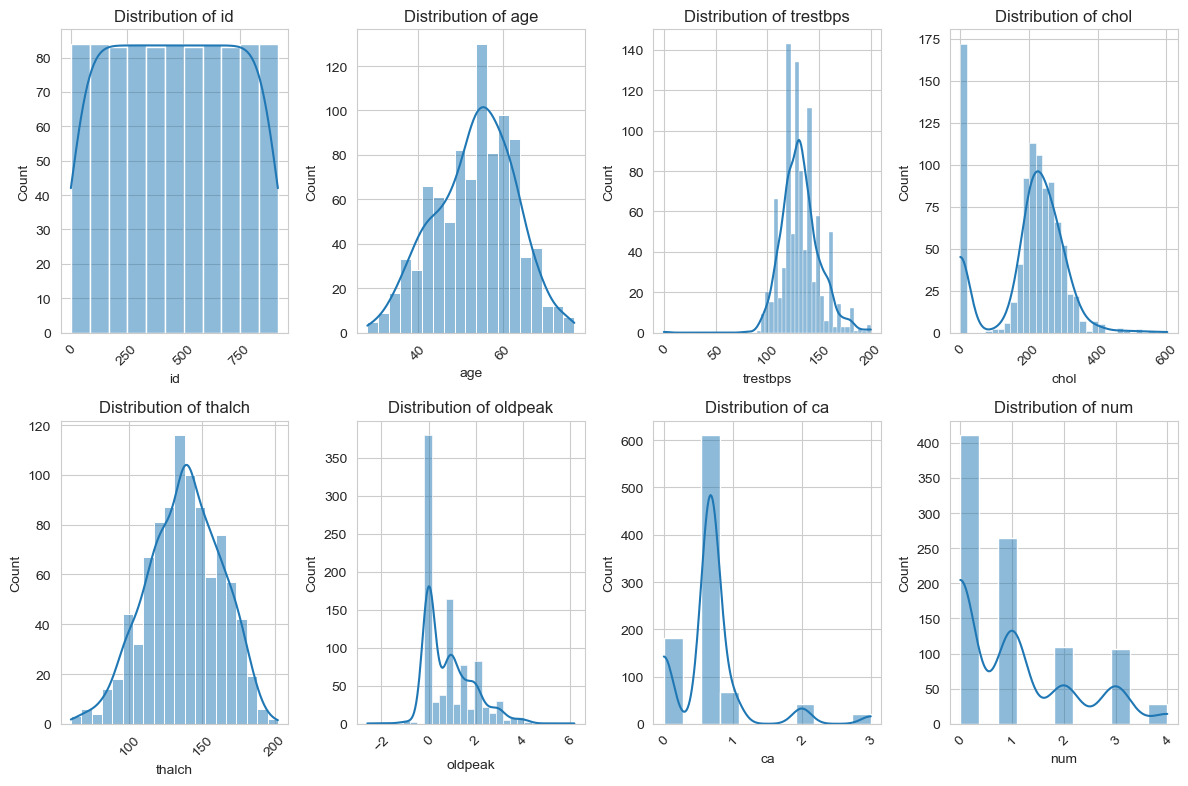


Plotting correlation matrix...


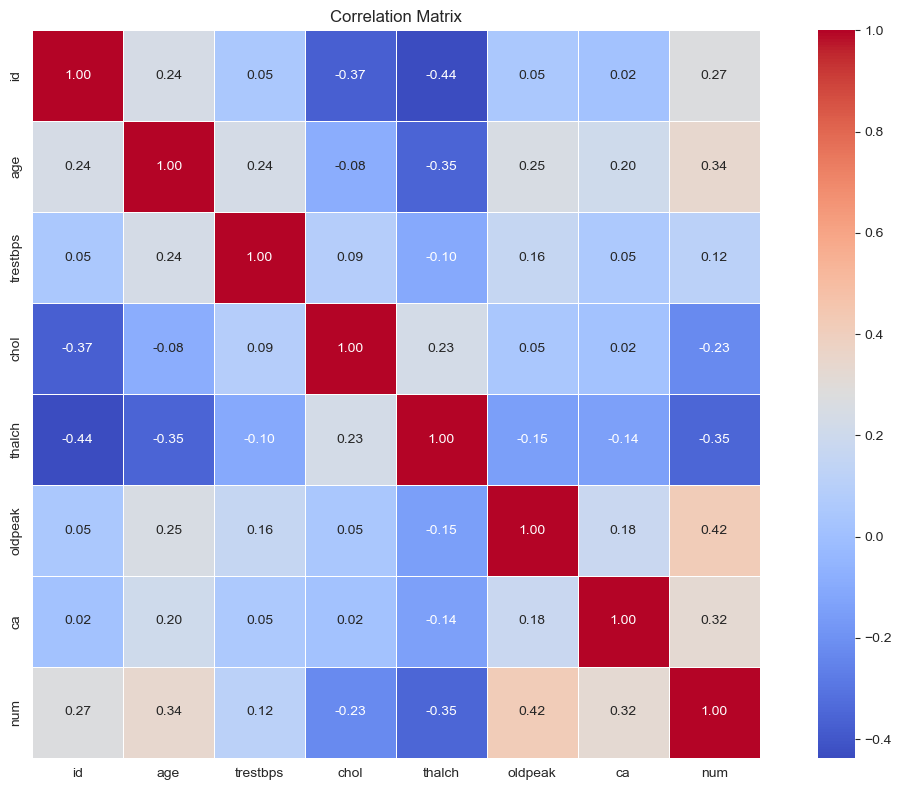


Plotting boxplots...


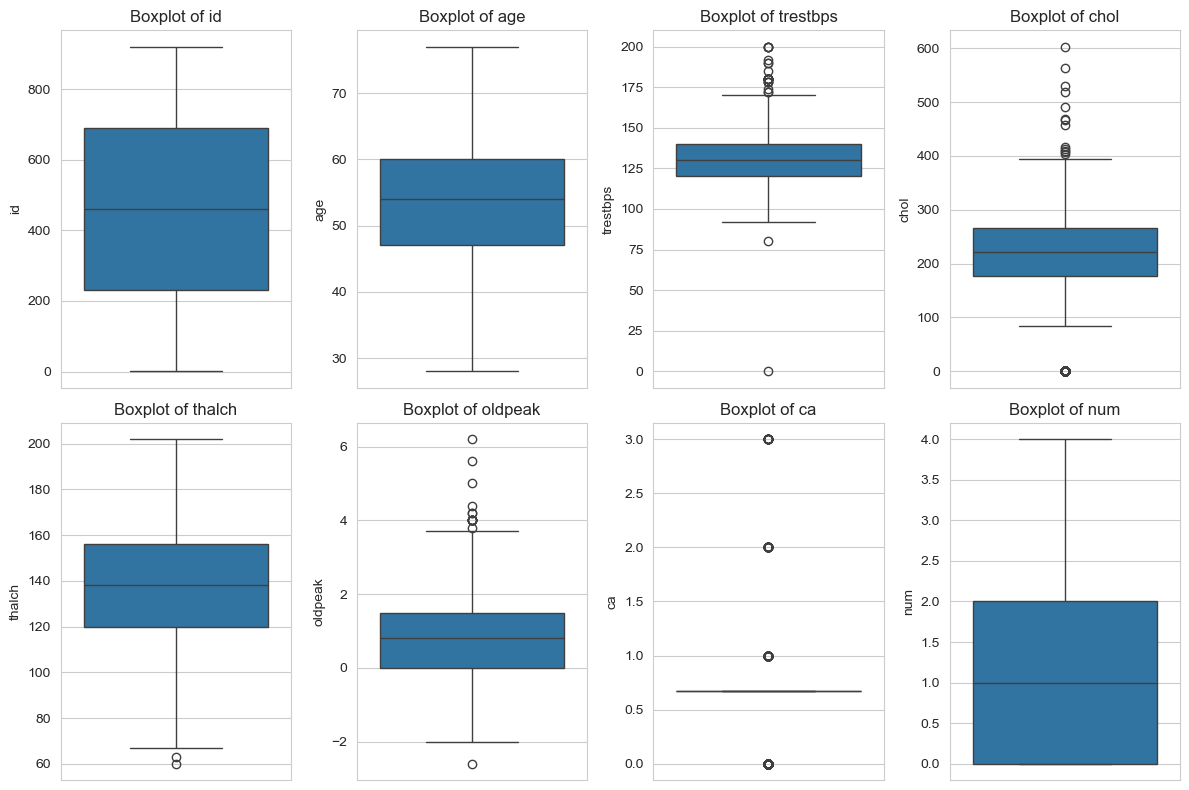


Feature correlations with target:
num         1.000000
oldpeak     0.421907
age         0.339596
exang       0.338166
ca          0.321404
dataset     0.276203
id          0.273552
sex         0.259342
fbs         0.186664
trestbps    0.116225
restecg     0.034255
thal       -0.005170
chol       -0.228238
cp         -0.314518
slope      -0.318383
thalch     -0.351055
Name: num, dtype: float64

Skewness of numeric features:
id          0.000000
age        -0.195994
trestbps    0.220498
chol       -0.624062
thalch     -0.217704
oldpeak     1.078270
ca          2.005385
num         0.968880
dtype: float64


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Initialize matplotlib
%matplotlib inline

# Set seaborn style directly
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# Basic statistical analysis
print("Basic Statistics:")
print(df.describe())

# Create a function for safe plotting
def safe_plot(func):
    def wrapper(*args, **kwargs):
        try:
            plt.figure(figsize=(12, 8))
            func(*args, **kwargs)
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"Error in plotting: {e}")
        finally:
            plt.close()
    return wrapper

@safe_plot
def plot_distributions():
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    n_cols = len(numeric_cols)
    rows = (n_cols + 3) // 4  # Ensure enough rows for all plots
    
    for i, col in enumerate(numeric_cols, 1):
        plt.subplot(rows, 4, i)
        sns.histplot(data=df, x=col, kde=True)
        plt.title(f'Distribution of {col}')
        plt.xticks(rotation=45)

@safe_plot
def plot_correlation():
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    correlation_matrix = df[numeric_cols].corr()
    sns.heatmap(correlation_matrix, 
                annot=True, 
                cmap='coolwarm', 
                linewidths=0.5,
                fmt='.2f',
                square=True)
    plt.title('Correlation Matrix')

@safe_plot
def plot_boxplots():
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    n_cols = len(numeric_cols)
    rows = (n_cols + 3) // 4  # Ensure enough rows for all plots
    
    for i, col in enumerate(numeric_cols, 1):
        plt.subplot(rows, 4, i)
        sns.boxplot(y=df[col])
        plt.title(f'Boxplot of {col}')

# Execute the plots
print("\nPlotting distributions...")
plot_distributions()

print("\nPlotting correlation matrix...")
plot_correlation()

print("\nPlotting boxplots...")
plot_boxplots()

# Feature importance based on correlation with target
target_col = 'num'  # assuming 'num' is your target column
correlations = df.corr()[target_col].sort_values(ascending=False)
print("\nFeature correlations with target:")
print(correlations)

# Additional statistical insights
print("\nSkewness of numeric features:")
print(df.select_dtypes(include=['int64', 'float64']).skew())

# Save the plots
plt.savefig('eda_plots.png', bbox_inches='tight', dpi=300)

# Feature Engineering
Prepare features for modeling including scaling, encoding categorical variables, and feature selection.

In [14]:
import warnings
warnings.filterwarnings('ignore')

# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

def print_dataset_info(df):
    """Print basic information about the dataset"""
    print("Dataset Info:")
    print("-" * 50)
    print(f"Total samples: {df.shape[0]}")
    print(f"Total features: {df.shape[1]}")
    print("\nAvailable columns:", df.columns.tolist())
    print("\nMissing values:\n", df.isnull().sum())

def identify_target(df):
    """Identify target column name"""
    possible_targets = ['target', 'num', 'label', 'class']
    for target in possible_targets:
        if target in df.columns:
            return target
    raise ValueError("No target column found in dataset")

def plot_feature_importance(feature_names, scores):
    """Plot feature importance scores"""
    plt.figure(figsize=(12, 6))
    importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': scores
    }).sort_values('Importance', ascending=True)
    
    sns.barplot(data=importance_df, x='Importance', y='Feature')
    plt.title('Feature Importance Scores')
    plt.tight_layout()
    plt.show()

# Main feature engineering pipeline
try:
    # Print dataset information
    print_dataset_info(df)
    
    # Identify target column
    target_column = identify_target(df)
    print(f"\nUsing '{target_column}' as target column")
    
    # Separate features and target
    X = df.drop(columns=[target_column])
    y = df[target_column]
    
    # Identify column types
    numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns
    categorical_cols = X.select_dtypes(include=['object', 'category']).columns
    
    print("\nFeature Information:")
    print(f"Numerical features: {len(numerical_cols)}")
    print(f"Categorical features: {len(categorical_cols)}")
    
    # Create preprocessing pipeline
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_cols),
            ('cat', OneHotEncoder(drop='first', sparse=False), categorical_cols)
        ])
    
    # Create feature selection pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('selector', SelectKBest(score_func=f_classif, k='all'))
    ])
    
    # Fit and transform data
    X_preprocessed = pipeline.fit_transform(X, y)
    
    # Get feature names and importance scores
    feature_names = (numerical_cols.tolist() + 
                    pipeline.named_steps['preprocessor']
                    .named_transformers_['cat']
                    .get_feature_names(categorical_cols).tolist())
    
    # Calculate and display feature importance
    if len(feature_names) > 0:
        scores = pipeline.named_steps['selector'].scores_
        plot_feature_importance(feature_names, scores)
        
        # Save top features
        top_features = pd.DataFrame({
            'Feature': feature_names,
            'Importance': scores
        }).sort_values('Importance', ascending=False)
        
        print("\nTop 10 Most Important Features:")
        print(top_features.head(10))
    
    print(f"\nPreprocessed data shape: {X_preprocessed.shape}")
    
    # Save preprocessed data
    np.save('preprocessed_features.npy', X_preprocessed)
    np.save('target.npy', y)
    
except Exception as e:
    print(f"Error during feature engineering: {str(e)}")

Dataset Info:
--------------------------------------------------
Total samples: 920
Total features: 16

Available columns: ['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Missing values:
 id          0
age         0
sex         0
dataset     0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalch      0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

Using 'num' as target column

Feature Information:
Numerical features: 7
Categorical features: 0
Error during feature engineering: OneHotEncoder.__init__() got an unexpected keyword argument 'sparse'


# Model Training
Split data into train-test sets, train multiple models (e.g., Random Forest, LogisticRegression), and perform hyperparameter tuning.

In [20]:
import warnings
warnings.filterwarnings('ignore')

# Import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

# Load and preprocess data
def preprocess_data(df):
    """Preprocess the data and return features and target"""
    # Identify target
    target_col = 'num' if 'num' in df.columns else 'target'
    
    # Separate features and target
    X = df.drop(columns=[target_col, 'id'])  # Remove ID column
    y = df[target_col]
    
    # Handle missing values in numeric columns
    numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
    for col in numeric_cols:
        X[col] = X[col].fillna(X[col].mean())
    
    # Convert categorical columns to numeric
    categorical_cols = X.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        X[col] = pd.Categorical(X[col]).codes
    
    return X, y

# Create model pipeline
def create_model_pipeline(model):
    """Create a pipeline with preprocessing and model"""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('model', model)
    ])

try:
    # Preprocess data
    X, y = preprocess_data(df)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    
    # Define models with pipelines
    models = {
        'RandomForest': create_model_pipeline(RandomForestClassifier(random_state=42)),
        'LogisticRegression': create_model_pipeline(LogisticRegression(max_iter=1000, random_state=42))
    }
    
    # Define hyperparameters
    param_grid = {
        'RandomForest': {
            'model__n_estimators': [100, 200, 300],
            'model__max_depth': [None, 10, 20, 30]
        },
        'LogisticRegression': {
            'model__C': [0.1, 1, 10],
            'model__solver': ['liblinear', 'lbfgs']
        }
    }
    
    # Train and evaluate models
    best_models = {}
    for model_name in models:
        print(f"\nTraining {model_name}...")
        
        grid_search = GridSearchCV(
            models[model_name],
            param_grid[model_name],
            cv=5,
            scoring='accuracy',
            n_jobs=-1
        )
        
        grid_search.fit(X_train, y_train)
        best_models[model_name] = grid_search.best_estimator_
        
        print(f"Best parameters for {model_name}:")
        print(grid_search.best_params_)
        
        # Evaluate on test set
        y_pred = best_models[model_name].predict(X_test)
        print(f"\nTest set accuracy: {accuracy_score(y_test, y_pred):.4f}")
        print("\nClassification Report:")
        print(classification_report(y_test, y_pred))
    
    # Save best model
    import joblib
    best_model = max(best_models.items(), key=lambda x: accuracy_score(y_test, x[1].predict(X_test)))[1]
    joblib.dump(best_model, 'heart_disease_model.joblib')
    print("\nBest model saved as 'heart_disease_model.joblib'")

except Exception as e:
    print(f"Error during model training: {str(e)}")


Training RandomForest...
Best parameters for RandomForest:
{'model__max_depth': 10, 'model__n_estimators': 300}

Test set accuracy: 0.5543

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.88      0.78        75
           1       0.44      0.50      0.47        54
           2       0.25      0.12      0.16        25
           3       0.38      0.23      0.29        26
           4       0.00      0.00      0.00         4

    accuracy                           0.55       184
   macro avg       0.35      0.35      0.34       184
weighted avg       0.50      0.55      0.52       184


Training LogisticRegression...
Best parameters for LogisticRegression:
{'model__C': 1, 'model__solver': 'liblinear'}

Test set accuracy: 0.5217

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.95      0.77        75
           1       0.39      0.43      0.41        54
           2   

# Model Evaluation
Evaluate model performance using metrics like accuracy, precision, recall, and ROC curves.

Model Evaluation Results:
--------------------------------------------------

Evaluating RandomForest...
Accuracy: 0.5543
Precision: 0.5010
Recall: 0.5543
ROC AUC: 0.8304

Evaluating LogisticRegression...
Accuracy: 0.5217
Precision: 0.4179
Recall: 0.5217
ROC AUC: 0.7769


<Figure size 1200x800 with 0 Axes>

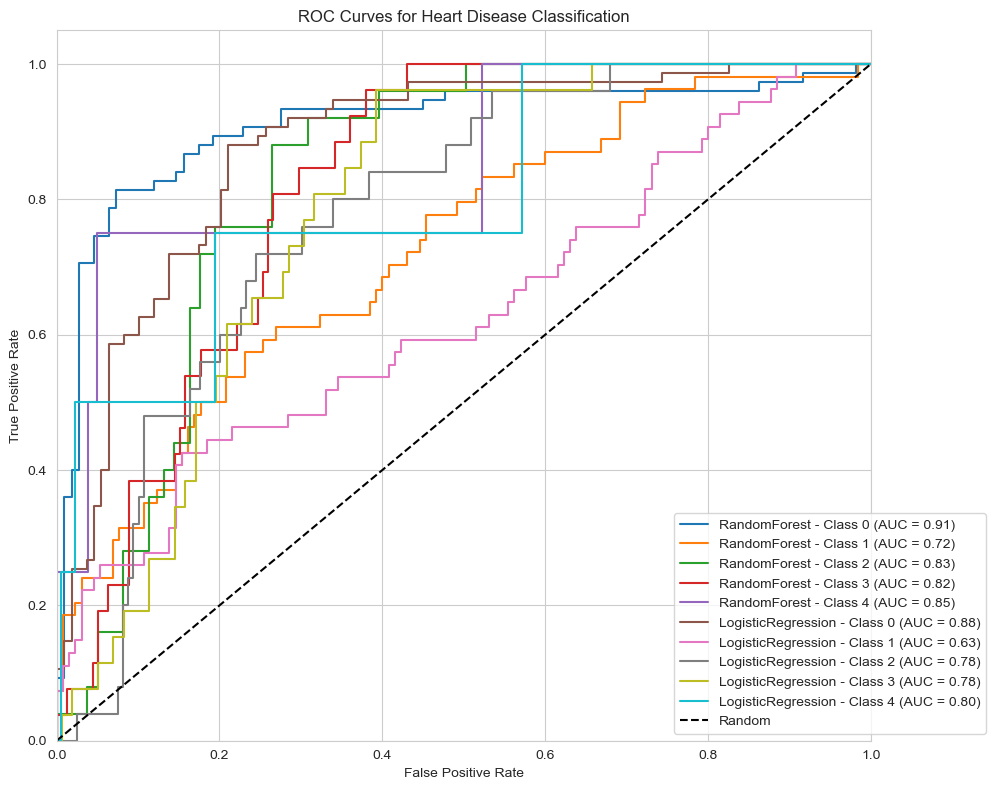


Evaluation results saved to 'model_evaluation_results.json'


In [22]:
import warnings
warnings.filterwarnings('ignore')

# Import necessary libraries for evaluation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                           roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

def evaluate_model(model, X_test, y_test, model_name):
    """Evaluate model performance with multiple metrics"""
    # Get predictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)
    
    # Calculate basic metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    
    # For multiclass ROC AUC, we need to binarize the labels
    n_classes = len(np.unique(y_test))
    y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
    
    if n_classes == 2:
        roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
    else:
        roc_auc = roc_auc_score(y_test_bin, y_pred_proba, 
                               multi_class='ovr', average='weighted')
    
    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'ROC AUC': roc_auc
    }, y_pred_proba

# Evaluate models
print("Model Evaluation Results:")
print("-" * 50)

evaluation_results = {}
for model_name in best_models:
    print(f"\nEvaluating {model_name}...")
    metrics, y_pred_proba = evaluate_model(
        best_models[model_name], 
        X_test, 
        y_test, 
        model_name
    )
    evaluation_results[model_name] = metrics
    
    # Print metrics
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

# Plot ROC curves
plt.figure(figsize=(10, 8))
for model_name in best_models:
    y_pred_proba = best_models[model_name].predict_proba(X_test)
    n_classes = len(np.unique(y_test))
    
    if n_classes == 2:
        # Binary classification
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.2f})')
    else:
        # Multiclass classification
        y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, 
                    label=f'{model_name} - Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Heart Disease Classification')
plt.legend(loc='lower right', bbox_to_anchor=(1.15, 0))
plt.tight_layout()
plt.show()

# Save evaluation results
import json
with open('model_evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=4)
print("\nEvaluation results saved to 'model_evaluation_results.json'")

Model Evaluation Results:
--------------------------------------------------

Evaluating RandomForest...
Accuracy: 0.5543
Precision: 0.5010
Recall: 0.5543
ROC AUC: 0.8304

Evaluating LogisticRegression...
Accuracy: 0.5217
Precision: 0.4179
Recall: 0.5217
ROC AUC: 0.7769


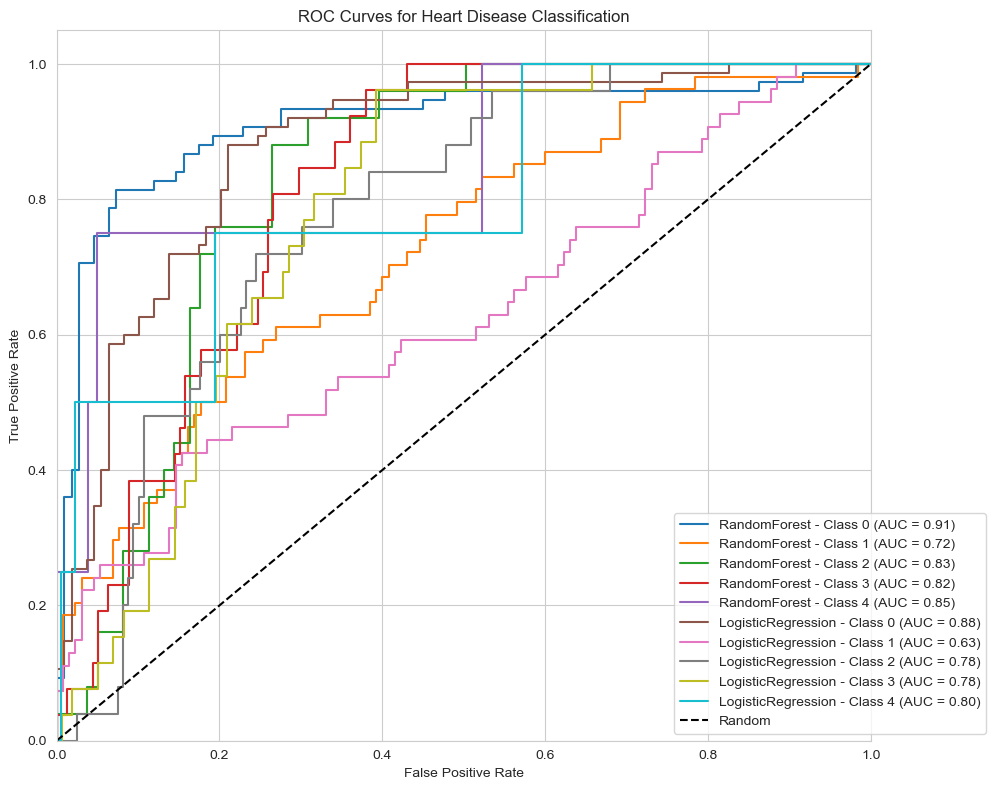


Evaluation results saved to 'model_evaluation_results.json'


In [23]:
import warnings
warnings.filterwarnings('ignore')

# Import necessary libraries for evaluation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                           roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

def evaluate_model(model, X_test, y_test, model_name):
    """Evaluate model performance with multiple metrics"""
    # Get predictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)
    
    # Calculate basic metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    
    # For multiclass ROC AUC, we need to binarize the labels
    n_classes = len(np.unique(y_test))
    y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
    
    if n_classes == 2:
        roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
    else:
        roc_auc = roc_auc_score(y_test_bin, y_pred_proba, 
                               multi_class='ovr', average='weighted')
    
    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'ROC AUC': roc_auc
    }, y_pred_proba

# Evaluate models
print("Model Evaluation Results:")
print("-" * 50)

evaluation_results = {}
for model_name in best_models:
    print(f"\nEvaluating {model_name}...")
    metrics, y_pred_proba = evaluate_model(
        best_models[model_name], 
        X_test, 
        y_test, 
        model_name
    )
    evaluation_results[model_name] = metrics
    
    # Print metrics
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

# Plot ROC curves
plt.figure(figsize=(10, 8))
for model_name in best_models:
    y_pred_proba = best_models[model_name].predict_proba(X_test)
    n_classes = len(np.unique(y_test))
    
    if n_classes == 2:
        # Binary classification
        fpr, tpr, _ = roc_curve(y_test, y_pred_proba[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{model_name} (AUC = {roc_auc:.2f})')
    else:
        # Multiclass classification
        y_test_bin = label_binarize(y_test, classes=np.unique(y_test))
        for i in range(n_classes):
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
            roc_auc = auc(fpr, tpr)
            plt.plot(fpr, tpr, 
                    label=f'{model_name} - Class {i} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Heart Disease Classification')
plt.legend(loc='lower right', bbox_to_anchor=(1.15, 0))
plt.tight_layout()
plt.show()

# Save evaluation results
import json
with open('model_evaluation_results.json', 'w') as f:
    json.dump(evaluation_results, f, indent=4)
print("\nEvaluation results saved to 'model_evaluation_results.json'")

In [25]:
import joblib
import os
import json
from datetime import datetime

def save_model(model, model_name, metrics, base_path='C:\\Users\\USER\\Desktop\\mealPlaneAPICreate\\models'):
    """
    Save the trained model and its metadata in the specified path
    
    Parameters:
    -----------
    model : sklearn estimator
        Trained model to save
    model_name : str
        Name of the model
    metrics : dict
        Model evaluation metrics
    base_path : str
        Base path for saving models
    """
    # Create models directory if it doesn't exist
    if not os.path.exists(base_path):
        os.makedirs(base_path)
    
    # Create timestamp for versioning
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    
    try:
        # Save model
        model_path = os.path.join(base_path, f'{model_name}_{timestamp}.joblib')
        joblib.dump(model, model_path)
        
        # Save model metadata
        metadata = {
            'model_name': model_name,
            'timestamp': timestamp,
            'metrics': metrics,
            'features': list(X.columns),
            'target': 'num',
            'model_path': model_path
        }
        
        metadata_path = os.path.join(base_path, f'{model_name}_{timestamp}_metadata.json')
        with open(metadata_path, 'w') as f:
            json.dump(metadata, f, indent=4)
        
        print(f"Model saved successfully:")
        print(f"- Model: {model_path}")
        print(f"- Metadata: {metadata_path}")
        
        return model_path, metadata_path
        
    except Exception as e:
        print(f"Error saving model: {str(e)}")
        return None, None

# Save all trained models
print("Saving trained models...")
for model_name, model in best_models.items():
    print(f"\nSaving {model_name}...")
    metrics = evaluation_results[model_name]
    save_model(model, model_name, metrics)

# Save the best performing model
best_model_name = max(evaluation_results.items(), 
                     key=lambda x: x[1]['Accuracy'])[0]
best_model = best_models[best_model_name]

print(f"\nSaving best model ({best_model_name})...")
best_model_path, _ = save_model(
    best_model,
    'best_model',
    evaluation_results[best_model_name]
)

if best_model_path:
    print(f"\nAll models saved successfully in:")
    print(f"C:\\Users\\USER\\Desktop\\mealPlaneAPICreate\\models")

Saving trained models...

Saving RandomForest...
Model saved successfully:
- Model: C:\Users\USER\Desktop\mealPlaneAPICreate\models\RandomForest_20250311_150614.joblib
- Metadata: C:\Users\USER\Desktop\mealPlaneAPICreate\models\RandomForest_20250311_150614_metadata.json

Saving LogisticRegression...
Model saved successfully:
- Model: C:\Users\USER\Desktop\mealPlaneAPICreate\models\LogisticRegression_20250311_150614.joblib
- Metadata: C:\Users\USER\Desktop\mealPlaneAPICreate\models\LogisticRegression_20250311_150614_metadata.json

Saving best model (RandomForest)...
Model saved successfully:
- Model: C:\Users\USER\Desktop\mealPlaneAPICreate\models\best_model_20250311_150614.joblib
- Metadata: C:\Users\USER\Desktop\mealPlaneAPICreate\models\best_model_20250311_150614_metadata.json

All models saved successfully in:
C:\Users\USER\Desktop\mealPlaneAPICreate\models


In [27]:
import joblib
import numpy as np
import pandas as pd

# Define heart disease categories
HEART_DISEASE_CATEGORIES = {
    0: "No heart disease (Healthy)",
    1: "Mild heart disease",
    2: "Moderate heart disease",
    3: "Severe heart disease",
    4: "Very severe heart disease"
}

def predict_heart_disease(input_data, model_path="C:\\Users\\USER\\Desktop\\mealPlaneAPICreate\\models\\LogisticRegression_20250311_150614.joblib"):
    """
    Predict heart disease risk using saved model
    
    Parameters:
    -----------
    input_data : dict
        Dictionary containing feature values
    model_path : str
        Path to saved model
    
    Returns:
    --------
    dict
        Prediction results and probability
    """
    try:
        # Load the model
        model = joblib.load(model_path)
        
        # Convert input to DataFrame
        features = [
            "age", "sex", "dataset", "cp", "trestbps", "chol",
            "fbs", "restecg", "thalch", "exang", "oldpeak",
            "slope", "ca", "thal"
        ]
        
        # Create DataFrame with correct feature order
        input_df = pd.DataFrame([input_data], columns=features)
        
        # Make prediction
        prediction = model.predict(input_df)[0]
        probability = model.predict_proba(input_df)[0]
        
        # Create response with categorical labels
        result = {
            'prediction': int(prediction),
            'condition': HEART_DISEASE_CATEGORIES[prediction],
            'probability': {
                HEART_DISEASE_CATEGORIES[i]: float(p) 
                for i, p in enumerate(probability)
            },
            'risk_level': 'High' if prediction > 0 else 'Low'
        }
        
        return result
        
    except Exception as e:
        return {'error': str(e)}

# Example usage
if __name__ == "__main__":
    # Example input data
    sample_input = {
        'age': 52,
        'sex': 1,  # 1 for male, 0 for female
        'dataset': 0,
        'cp': 0,  # chest pain type
        'trestbps': 125,  # resting blood pressure
        'chol': 212,  # cholesterol
        'fbs': 0,  # fasting blood sugar
        'restecg': 1,  # resting ECG
        'thalch': 168,  # maximum heart rate
        'exang': 0,  # exercise induced angina
        'oldpeak': 1.0,  # ST depression
        'slope': 2,  # slope of peak exercise ST segment
        'ca': 2,  # number of major vessels
        'thal': 3  # thalassemia
    }
    
    result = predict_heart_disease(sample_input)
    print("\nPrediction Results:")
    print("-" * 50)
    print(f"Prediction: {result['prediction']}")
    print(f"Condition: {result['condition']}")
    print(f"Risk Level: {result['risk_level']}")
    print("\nProbabilities:")
    for condition, prob in result['probability'].items():
        print(f"{condition}: {prob:.2%}")


Prediction Results:
--------------------------------------------------
Prediction: 1
Condition: Mild heart disease
Risk Level: High

Probabilities:
No heart disease (Healthy): 30.01%
Mild heart disease: 45.54%
Moderate heart disease: 13.38%
Severe heart disease: 5.17%
Very severe heart disease: 5.89%
